In [8]:
import xhorizon as xh
import matplotlib.pyplot as plt
import numpy as np

for name in dir(xh):
    print(name)


__builtins__
__cached__
__doc__
__file__
__loader__
__name__
__package__
__path__
__spec__
__version__
block
cm
cornermask
curve
diagram
diagram_tools
evap
fill
func_test
junc
mask
mf
newfig
np
plt
pubrc
reg
region
shell_junction
tortoise
version



This part is slow, reference F(r) arrays being calculated by integration...
...done.

{'Type': 'Schwarzschild', 'Metric Function': '$f(r) = 1 - R/r$', 'Parameters': '$R=2.0$'}


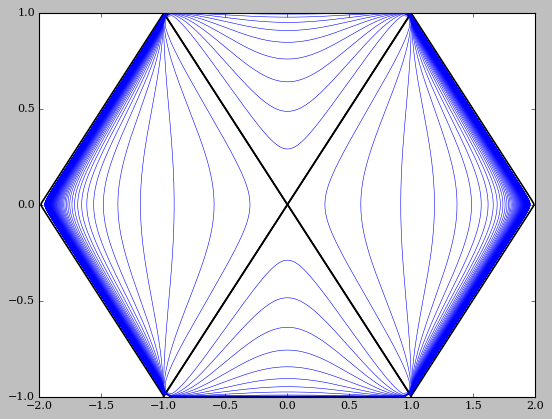

In [9]:
M = 1.0
f = xh.mf.schwarzschild(2*M)
reg = xh.reg.MAXreg(f)
print(f.info)

reg.rplot()


This part is slow, reference F(r) arrays being calculated by integration...


c:\Users\przyb\anaconda3\envs\gr\Lib\site-packages\xhorizon\tortoise\tortoise.py:214: IntegrationWarning: Extremely bad integrand behavior occurs at some points of the
  integration interval.
  val, abserr = spint.quad(func,a,b, limit=100)
c:\Users\przyb\anaconda3\envs\gr\Lib\site-packages\xhorizon\tortoise\tortoise.py:214: IntegrationWarning: The occurrence of roundoff error is detected, which prevents 
  the requested tolerance from being achieved.  The error may be 
  underestimated.
  val, abserr = spint.quad(func,a,b, limit=100)


...done.



c:\Users\przyb\anaconda3\envs\gr\Lib\site-packages\xhorizon\diagram_tools\coord_transf.py:109: RuntimeWarning: overflow encountered in exp
  H = k**(-1) * ( np.exp(k*s) - 1. )
c:\Users\przyb\anaconda3\envs\gr\Lib\site-packages\xhorizon\diagram_tools\block_masks.py:59: RuntimeWarning: invalid value encountered in multiply
  rstar_limits = - np.inf * np.sign(func.kj)
c:\Users\przyb\anaconda3\envs\gr\Lib\site-packages\xhorizon\diagram_tools\coord_transf.py:109: RuntimeWarning: overflow encountered in exp
  H = k**(-1) * ( np.exp(k*s) - 1. )
c:\Users\przyb\anaconda3\envs\gr\Lib\site-packages\xhorizon\diagram_tools\coord_transf.py:109: RuntimeWarning: overflow encountered in exp
  H = k**(-1) * ( np.exp(k*s) - 1. )
c:\Users\przyb\anaconda3\envs\gr\Lib\site-packages\xhorizon\diagram_tools\block_masks.py:59: RuntimeWarning: invalid value encountered in multiply
  rstar_limits = - np.inf * np.sign(func.kj)


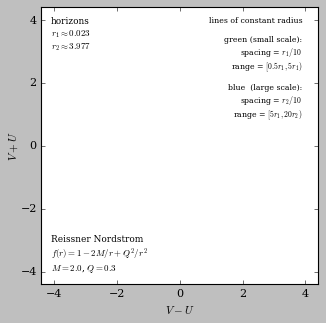

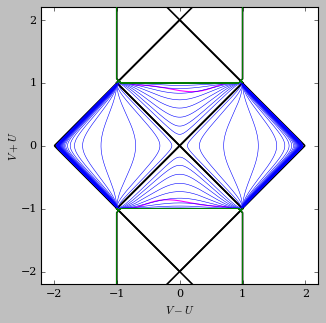

In [10]:
f = xh.mf.reissner_nordstrom(M=2, Q=0.3)
reg = xh.reg.MAXreg(f)

xh.newfig()

metric_info  = "\n".join([f.info[key] for key in ["Type", "Metric Function", "Parameters"]])
horizon_info = "\n".join(["horizons", r"$r_1 \approx %.3f$"%(f.rj[1]),r"$r_2 \approx %.3f$"%(f.rj[2])])
rlines_info  = "lines of constant radius\n\n"
rlines_info += "\n".join(["green (small scale):", r"spacing = $r_1/10$", r"range = $[0.5r_1, 5r_1)$", "\n"])
rlines_info += "\n".join(["blue  (large scale):", r"spacing = $r_2/10$", r"range = $[5r_1, 20r_2)$"])

plt.annotate(text=metric_info,  xy=(-4.1,-4.1), ha='left',  va='bottom', size=8)
plt.annotate(text=horizon_info, xy=(-4.1, 4.1), ha='left',  va='top',    size=8)
plt.annotate(text=rlines_info,  xy=( 3.9, 4.1), ha='right', va='top',    size=7)

t = np.linspace(-50,50,1001)
r = 1.5 + 0.25*np.sin(t)

crv = xh.curve()
crv.tr = np.array([t,r])
crv.sty = dict(c='magenta', lw=1, zorder=0)

for b in reg.blocks:
    b.add_curves_tr([crv])

xh.newfig(sqaxis=2)
reg.rplot()
plt.savefig("out.png", dpi = 250)

In [11]:
rh = 1
lamb = rh

def r_star_of_r(r, rh=rh):
    r = np.asarray(r, dtype=float)

    arg = np.abs(r/rh - 1)
    thresh = np.exp(np.finfo(float).min)
    # thresh = 10**(-2)
    m = arg > thresh
    r_star = np.full_like(r, -np.inf)
    r_star[m] = r[m] + rh*np.log(arg[m])

    
    return r_star


def t_of_tau(tau, r, height_fun, lamb=lamb): # calculates t given a regular time tau obtained by height function
    return lamb*(tau - height_fun(r))

def height_hyperbolic(r, rh=rh, lamb=lamb):  # height function for which tau = t + h(r) behaves hyperbolicaly 
    r = np.asarray(r, dtype=float)

    arg1 = np.abs(r/rh - 1)
    arg2 = r/rh

    log1 = np.full_like(r, -np.inf)
    log2 = np.full_like(r, -np.inf)
    thresh = np.exp(np.finfo(float).min)
    mask1 = arg1 > thresh
    mask2 = arg2 > thresh

    log1[mask1] = np.log(arg1[mask1])
    log2[mask2] = np.log(arg2[mask2])

    return (rh*log1 - 2*rh*log2 - r)/lamb


def t_r_star_from_hyperbolic(r, tau, height_fun, lamb=lamb):
    t = lamb*(tau - height_fun(r))
    r_star = r_star_of_r(r)
    return t, r_star


This part is slow, reference F(r) arrays being calculated by integration...
...done.



c:\Users\przyb\anaconda3\envs\gr\Lib\site-packages\xhorizon\diagram_tools\block_masks.py:59: RuntimeWarning: invalid value encountered in multiply
  rstar_limits = - np.inf * np.sign(func.kj)


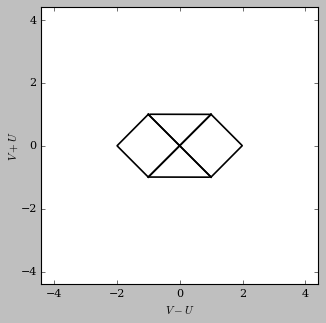

In [12]:
f = xh.mf.schwarzschild(M)

reg = xh.reg.MAXreg(f, boundary=True, rlines=False, uvgrid=False)


# v = np.linspace(-50, 50, 1001)
# u = np.zeros_like(v)


# crv = xh.curve()
# crv.uv = np.array([u,v])
# crv.sty = dict(c='magenta', lw=1, zorder=0)


sigma_i = 10**(-6)
sigma = np.linspace(sigma_i, 50, 10000)
tau = np.zeros_like(sigma)
r = 1/sigma

t, r = t_r_star_from_hyperbolic(r, tau, height_hyperbolic)

crvt = xh.curve()
crvt.tr = np.array([t, r])
crvt.sty = dict(c='blue', lw=1, zorder=0)

for b in reg.blocks:
    # b.add_curves_uv([crv])
    b.add_curves_tr([crvt])

xh.newfig(sqaxis=4)

reg.rplot()
plt.savefig("out.png")


In [13]:
for b in reg.blocks:
    print(b)